# Selection on structural variants — Figure 1, complete-site version

The same figure as `sv_main_fig1.ipynb` with one change: every class is restricted to variants **called
in all 231 founders**. In the pangenome a founder is uncalled at a bubble when its assembly takes a
different path there, and the founder whose haplotype diverges locally is typically the one carrying the
rare allele. So a site missing even a few founders has usually lost its rare tail (diagnostic printed
below), and the 90%-call version mixes such sites, in proportions that differ between classes, with
complete ones. Complete sites are the like-for-like set. Cost: fewer variants (retained fractions
printed), and Tajima's *D* sits near its floor there, so panel (b) shows the share of singletons instead,
with *D* in the table.

Shared code with the other figure notebooks: `_main_fig_common.py`; this builder is
`_build_main_fig1_complete_nb.py`; the 90%-call notebook is unchanged.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'figure.dpi':120,'font.size':8,'axes.linewidth':0.6,'savefig.bbox':'tight'})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
KC={"snp":"0.15","indel":"0.62","ins":"#D95F02","del":"#1B9E77"}; KL={"snp":"SNPs","indel":"short indels","ins":"insertions","del":"deletions"}
OC={"cold-specific":"#2166AC","shared":"0.45","warm-specific":"#B2182B"}
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.9",lw=0.6,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def panel(ax,letter): ax.annotate(letter,xy=(-0.12,1.04),xycoords="axes fraction",fontsize=11,fontweight="bold")
rng=np.random.default_rng(0)
D=pd.read_csv(f"{G}/sv_event_catalog.csv"); PALL=np.load(f"{G}/sv_event_catalog_p_poolaf.npy")   # kMate pool allele frequencies (seed mix + each garden)
ok=D.passes.to_numpy(); E=D[ok].reset_index(drop=True); PE=PALL[ok]
CS=np.load(f"{G}/classic_sfs.npz"); M=int(CS["M"])
def maf(name): c=CS[f"{name}_c"].astype(float); k=CS[f"{name}_k"].astype(float); f=c/k; return np.minimum(f,1-f)
def tajD(names):
    # Tajima's D of a class, directly from its variants (no projection): per variant, c carriers among k called founders
    names=[names] if isinstance(names,str) else names
    c=np.concatenate([CS[f"{n}_c"] for n in names]).astype(float); k=np.concatenate([CS[f"{n}_k"] for n in names]).astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1))
    return D(h),h,D
def tajD_matched(snp_name,sv_name,per=50,seed=0):
    # Tajima's D of SNPs re-weighted to the SV class's call-rate distribution: for every value of k (called founders) among the
    # SV events, draw up to per x (number of events with that k) SNPs with exactly that k. Bootstrap CI over the drawn SNPs.
    r=np.random.default_rng(seed); cs=CS[f"{snp_name}_c"].astype(int); ks=CS[f"{snp_name}_k"].astype(int); kv=CS[f"{sv_name}_k"].astype(int)
    pick=[]
    for kk,n in zip(*np.unique(kv,return_counts=True)):
        pool=np.where(ks==kk)[0]
        if pool.size: pick.append(r.choice(pool,min(per*n,pool.size),replace=False))
    pick=np.concatenate(pick); c=cs[pick].astype(float); k=ks[pick].astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1)); bs=[D(r.choice(h,h.size)) for _ in range(100)]
    return D(h),np.percentile(bs,2.5),np.percentile(bs,97.5)
def tajD_ci(names,B=300):
    d,h,D=tajD(names)
    if h.size>20000:                                  # large SNP classes: CI is negligible, fewer draws
        bs=[D(rng.choice(h,h.size)) for _ in range(40)]
    else: bs=[D(rng.choice(h,h.size)) for _ in range(B)]
    return d,np.percentile(bs,2.5),np.percentile(bs,97.5)
print(f"events passing: {len(E):,} ({(E.kind=='ins').sum():,} insertions, {(E.kind=='del').sum():,} deletions)")
# robustness checks (`_sv_main_figures_checks.py`): matched-SNP-set null for the load statistic, founder
# origin in the burden model, spectra without singletons
CKM=pd.read_csv(f"{G}/main_fig_checks_lmm.csv").set_index("check")
CKS=pd.read_csv(f"{G}/main_fig_checks_nosingleton.csv")
pfmt=lambda p: "p < 0.001" if p<=0.001 else f"p = {p:.2g}"


events passing: 18,418 (12,981 insertions, 5,437 deletions)


In [2]:

# COMPLETE SITES: keep only variants called in all 231 founders (every class, same rule). Missing calls are not random here --
# the uncalled founder is typically the rare-allele carrier -- so incompletely called sites have lost their rare tail.
CS_ALL=CS; N_ALL={n[:-2]:CS_ALL[n].size for n in CS_ALL.files if n.endswith("_c")}
CS={}
for n in CS_ALL.files:
    if n.endswith("_c") or n.endswith("_k"):
        base=n[:-2]; m=CS_ALL[f"{base}_k"]==231; CS[n]=CS_ALL[n][m]
    else: CS[n]=CS_ALL[n]
ret=pd.DataFrame({b:dict(n_all=N_ALL[b],n_complete=CS[f"{b}_c"].size,retained=CS[f"{b}_c"].size/N_ALL[b]) for b in N_ALL}).T
print("variants called in all 231 founders, per class:"); print(ret[ret.index.str.match(r"^(snp_(syn|nonsyn|CDS|UTR|intron|promoter|intergenic|TE)|ins_|del_)")].round(3).to_string())


variants called in all 231 founders, per class:
                   n_all  n_complete  retained
snp_syn         394676.0    180908.0     0.458
snp_nonsyn      404580.0    208453.0     0.515
snp_CDS         811580.0    395493.0     0.487
snp_UTR         275107.0    119693.0     0.435
snp_intron      747384.0    327610.0     0.438
snp_TE          579876.0    114993.0     0.198
snp_promoter    879942.0    329087.0     0.374
snp_intergenic  443065.0    148809.0     0.336
ins_CDS           1257.0       492.0     0.391
ins_UTR           1320.0       488.0     0.370
ins_intron        2274.0       803.0     0.353
ins_TE            2980.0       714.0     0.240
ins_promoter      8530.0      2980.0     0.349
ins_intergenic    3641.0      1214.0     0.333
del_CDS           1125.0       135.0     0.120
del_UTR            649.0        80.0     0.123
del_intron        1225.0       177.0     0.144
del_TE            1368.0        38.0     0.028
del_promoter      2268.0       188.0     0.083
del_intergen

## Figure 1 — Purifying selection on SVs in the founders

**(a)** Folded site-frequency spectra as cumulative distributions of minor-allele frequency, for
insertions and deletions in coding sequence (left) and in introns (right), against the neutral
reference (synonymous SNPs, dashed grey) and the known-selected comparator (nonsynonymous SNPs, black).
A curve above the neutral one = a class shifted towards rare variants, the footprint of purifying
selection. Two-sample Kolmogorov–Smirnov *D* against synonymous SNPs in each panel.
**(b)** Share of singletons (folded: minor-allele count 1) per genomic context, all SNPs of the context (black) with the insertions and deletions of the same context (95% bootstrap CI); vertical lines = synonymous (dashed) and nonsynonymous (dotted) SNPs. **(c)** Where each class is found:
share of the class in each context divided by the context's share of genomic length (1 = uniform
placement), insertions and deletions against SNPs.

*Statistics.* Folded MAF per variant = min(c/k, 1 − c/k), c carriers among k called founders
(k = 231, 1 ≤ c ≤ 230; singletons included). Tajima's *D* per class from the variants' allele counts
(Tajima 1989; identical to scikit-allel on complete data; missing calls handled per site), bootstrap CI
over variants; SNP references in (b) drawn to the SV class's call-rate distribution (up to 50 SNPs per
event with exactly the same number of called founders); synonymous / nonsynonymous calls from the reference codon and the codon carrying the
ALT base (representative gene model).

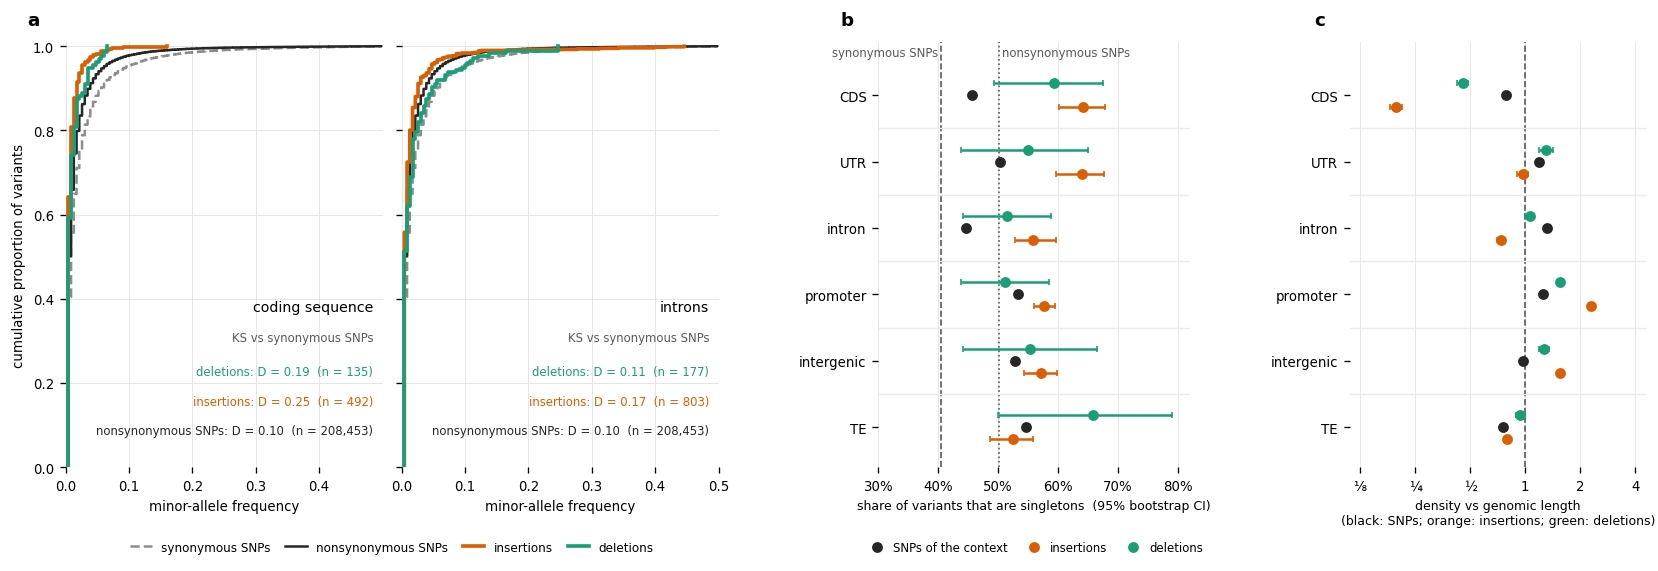

Figure 1a  cumulative spectra; KS vs synonymous SNPs:
context                cls      n  maf_lt1  maf_lt5  maf_lt10  KS_D  KS_p
    CDS    synonymous SNPs 180908    0.557    0.882     0.954 0.000 1.000
    CDS nonsynonymous SNPs 208453    0.659    0.934     0.979 0.102 0.000
    CDS         insertions    492    0.809    0.982     0.998 0.253 0.000
    CDS          deletions    135    0.741    0.963     1.000 0.188 0.000
 intron    synonymous SNPs 180908    0.557    0.882     0.954 0.000 1.000
 intron nonsynonymous SNPs 208453    0.659    0.934     0.979 0.102 0.000
 intron         insertions    803    0.725    0.958     0.984 0.168 0.000
 intron          deletions    177    0.621    0.904     0.955 0.110 0.026

neutral reference check — synonymous / nonsynonymous vs the stricter 4-fold / 0-fold sites:
       cls      n  maf_lt5   TajD
   snp_syn 180908    0.882 -2.360
 snp_4fold 103261    0.882 -2.353
snp_nonsyn 208453    0.934 -2.606
 snp_0fold 179163    0.935 -2.612

Figure 1b  Tajim

In [3]:

REF=maf("snp_syn")
def ecdf(a,v,**k):
    v=np.sort(v); a.step(np.r_[v[0],v],np.r_[0,np.arange(1,v.size+1)/v.size],where="post",**k)
fig=plt.figure(figsize=(17,4.6)); gs_=fig.add_gridspec(1,3,width_ratios=[2.2,1.05,1],wspace=0.38)
GSH=pd.read_csv(f"{G}/context_genome_share.csv").set_index("context").share.reindex(CTX).to_numpy()
S=np.load(f"{G}/sv_sfs_context_origin_event.npz"); m=S["snp_n"]>=2; ns=np.bincount(S["snp_ctx"][m],minlength=6); snp_sh=ns/ns.sum(); rs=snp_sh/GSH
TD={name:tajD_ci(name) for name in ["snp_syn","snp_nonsyn","snp_4fold","snp_0fold"]+[f"{k}_{x}" for k in ("snp","ins","del") for x in CTX]}
order=["TE","intergenic","promoter","intron","UTR","CDS"]; order_c=order                # same fixed order in (b) and (c): CDS at the bottom
OFF={"ins":-0.18,"del":0.18}; SF=[]; DENS={}
# (a) folded SFS as cumulative distributions: insertions and deletions together, coding sequence and introns apart
gsa=gs_[0,0].subgridspec(1,2,wspace=0.06); a1=fig.add_subplot(gsa[0,0]); a2=fig.add_subplot(gsa[0,1],sharey=a1)
for a,x,ttl in ((a1,"CDS","coding sequence"),(a2,"intron","introns")):
    style(a); txt=[]
    for name,lab,col,ls,lw in (("snp_syn","synonymous SNPs","0.55","--",1.5),("snp_nonsyn","nonsynonymous SNPs","0.15","-",1.5),(f"ins_{x}","insertions",KC["ins"],"-",2.2),(f"del_{x}","deletions",KC["del"],"-",2.2)):
        v=maf(name); ks=stats.ks_2samp(v,REF); ecdf(a,v,color=col,ls=ls,lw=lw,label=lab)
        if name!="snp_syn": txt.append((f"{lab}: D = {ks.statistic:.2f}  (n = {v.size:,})",col))
        SF.append(dict(context=x,cls=lab,n=v.size,maf_lt1=(v<0.01).mean(),maf_lt5=(v<0.05).mean(),maf_lt10=(v<0.10).mean(),KS_D=ks.statistic,KS_p=ks.pvalue))
    a.set_xlim(0,0.5); a.set_ylim(0,1.01); a.set_xlabel("minor-allele frequency"); a.set_xticks([0,0.1,0.2,0.3,0.4]+([0.5] if x=="intron" else []))
    a.annotate(ttl,xy=(0.97,0.36),xycoords="axes fraction",ha="right",va="bottom",fontsize=8.5)
    a.annotate("KS vs synonymous SNPs",xy=(0.97,0.29),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color="0.35")
    for q,(s_,col) in enumerate(txt[::-1]): a.annotate(s_,xy=(0.97,0.21-0.07*q),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color=col)
a1.set_ylabel("cumulative proportion of variants"); a2.tick_params(labelleft=False); panel(a1,"a")
h_,l_=a1.get_legend_handles_labels(); a1.legend(h_,l_,frameon=False,fontsize=7.2,loc="upper center",bbox_to_anchor=(1.03,-0.15),ncol=4,columnspacing=1.2,handlelength=1.8)
# (b) share of singletons (folded: minor-allele count 1) per class and context, bootstrap CI; SNPs of the context in black
def single(name,B=300):
    c=CS[f"{name}_c"].astype(int); k=CS[f"{name}_k"].astype(int); s1=(np.minimum(c,k-c)==1).astype(float)
    bs=[rng.choice(s1,s1.size).mean() for _ in range(B if s1.size<20000 else 40)]; return s1.mean(),np.percentile(bs,2.5),np.percentile(bs,97.5),s1.size
a=fig.add_subplot(gs_[0,1]); style(a,axis="x"); panel(a,"b"); SG={}
for name,lab,ls in (("snp_syn","synonymous SNPs","--"),("snp_nonsyn","nonsynonymous SNPs",":")):
    v=single(name); SG[name]=v; a.axvline(v[0],color="0.35",lw=1,ls=ls); a.annotate(lab,xy=(v[0]+(0.004 if name=="snp_nonsyn" else -0.004),len(order)-0.45),fontsize=7,ha="left" if name=="snp_nonsyn" else "right",va="bottom",color="0.35")
for i,x in enumerate(order):
    s_=single(f"snp_{x}"); SG[f"snp_{x}"]=s_; a.errorbar(s_[0],i,xerr=[[s_[0]-s_[1]],[s_[2]-s_[0]]],fmt="o",color=KC["snp"],ms=5.5,capsize=2,zorder=4)
    for k in ("ins","del"):
        v=single(f"{k}_{x}"); SG[f"{k}_{x}"]=v; y=i+OFF[k]
        a.errorbar(v[0],y,xerr=[[v[0]-v[1]],[v[2]-v[0]]],fmt="o",color=KC[k],ms=5.5,capsize=2,zorder=3)
    if i<len(order)-1: a.axhline(i+0.5,color="0.92",lw=0.8)
a.set_yticks(range(len(order))); a.set_yticklabels(order); a.set_ylim(-0.6,len(order)-0.2); a.set_xlim(0.30,0.82)
for k,lab in (("snp","SNPs of the context"),("ins","insertions"),("del","deletions")): a.errorbar([],[],fmt="o",color=KC[k],ms=5.5,label=lab)
a.legend(frameon=False,fontsize=7,loc="upper center",bbox_to_anchor=(0.5,-0.15),ncol=3,columnspacing=1.2,handletextpad=0.4)
a.set_xlabel("share of variants that are singletons  (95% bootstrap CI)",fontsize=7.5); a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
gap=TD["snp_nonsyn"][0]-TD["snp_syn"][0]; DD_={}
# (c) where they are found: share in context / share of genomic length
a=fig.add_subplot(gs_[0,2]); style(a,axis="x"); panel(a,"c"); a.axvline(1,color="0.35",lw=1,ls="--")
for k in ("ins","del"):
    nk=E[E.kind==k].context.value_counts().reindex(CTX).to_numpy(); sh=nk/nk.sum(); rk=sh/GSH; DENS[KL[k]]=rk
    for j,x in enumerate(order_c):
        i=CTX.index(x); y=j+OFF[k]
        a.errorbar(rk[i],y,xerr=1.96*np.sqrt(sh[i]*(1-sh[i])/nk.sum())/GSH[i],fmt="o",color=KC[k],ms=5.5,capsize=2,zorder=3)
for j,x in enumerate(order_c):
    i=CTX.index(x); a.errorbar(rs[i],j,xerr=1.96*np.sqrt(snp_sh[i]*(1-snp_sh[i])/ns.sum())/GSH[i],fmt="o",color=KC["snp"],ms=5.5,capsize=2,zorder=4)
    if j<5: a.axhline(j+0.5,color="0.92",lw=0.8)
a.set_xscale("log",base=2); a.set_xticks([0.125,0.25,0.5,1,2,4]); a.set_xticklabels(["⅛","¼","½","1","2","4"]); a.set_xlim(0.11,4.6)
a.set_yticks(range(6)); a.set_yticklabels(order_c); a.set_ylim(-0.6,5.8); a.set_xlabel("density vs genomic length\n(black: SNPs; orange: insertions; green: deletions)",fontsize=7.5)
fig.savefig(f"{G}/plots/main_fig1_complete.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{G}/plots/main_fig1_complete.pdf",bbox_inches="tight"); plt.show()
print("Figure 1a  cumulative spectra; KS vs synonymous SNPs:"); print(pd.DataFrame(SF).drop_duplicates(["context","cls"]).round(3).to_string(index=False))
print("\nneutral reference check — synonymous / nonsynonymous vs the stricter 4-fold / 0-fold sites:")
print(pd.DataFrame([dict(cls=n_,n=maf(n_).size,maf_lt5=(maf(n_)<0.05).mean(),TajD=TD[n_][0]) for n_ in ("snp_syn","snp_4fold","snp_nonsyn","snp_0fold")]).round(3).to_string(index=False))
print("\nFigure 1b  Tajima's D [95% CI]:"); print(pd.DataFrame({k_:dict(D=v[0],lo=v[1],hi=v[2]) for k_,v in TD.items()}).T.round(2).to_string())
print("\nFigure 1b  share of singletons [95% CI] and Tajima's D, complete sites:")
print(pd.DataFrame({k_:dict(n=v[3],singletons=v[0],lo=v[1],hi=v[2],TajD=TD[k_][0]) for k_,v in SG.items()}).T.round(3).to_string())
print("\nFigure 1c  share / genomic share:"); print(pd.DataFrame(dict(genome=GSH,SNPs=rs,**DENS),index=CTX).round(2).to_string())
# reading frame (not drawn): share of events whose length is a multiple of 3 (1/3 expected outside coding sequence)
I=E[E.kind=="ins"]; C=I[I.context=="CDS"]; rows=[]
for lab,d in (("CDS insertions, gene duplicate",C[C.seq_class=="gene_dup"]),("CDS insertions, TE-derived",C[C.seq_class=="te_derived"]),("all CDS insertions",C),
              ("CDS deletions",E[(E.kind=="del")&(E.context=="CDS")]),("insertions, other contexts",I[I.context!="CDS"])):
    x_=int((d.size_bp%3==0).sum()); n=len(d); ci=stats.binomtest(x_,n,1/3).proportion_ci(); rows.append(dict(group=lab,n=n,in_frame=x_/n,lo=ci.low,hi=ci.high))
print("\nreading frame (not drawn):"); print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nrobustness — with singletons (1) and without (minor-allele count >= 2): share MAF < 5%, KS D vs synonymous SNPs")
print(CKS.pivot(index="cls",columns="min_minor_count",values=["maf_lt5","KS_D"]).reindex(["snp_syn","snp_nonsyn","ins_CDS","ins_UTR","ins_intron","ins_TE","ins_promoter","ins_intergenic","del_CDS"]).round(3).to_string())


In [4]:

# why complete sites: spectrum shape by number of called founders, within a class (the 90% version mixes these)
def Dk(c,k):
    c=c.astype(float); k=k.astype(float); h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2); S=h.size
    return (h.sum()-S/a1)/np.sqrt(e1*S+e2*S*(S-1))
rows=[]
for name in ("snp_syn","snp_nonsyn","snp_CDS","snp_TE","ins_CDS","del_CDS"):
    c=CS_ALL[f"{name}_c"].astype(int); k=CS_ALL[f"{name}_k"].astype(int)
    for lo,hi in ((231,231),(229,230),(225,228),(218,224),(208,217)):
        m=(k>=lo)&(k<=hi)
        if m.sum()>30: rows.append(dict(cls=name,called=f"{lo}-{hi}" if lo<hi else "231",n=int(m.sum()),singletons=(np.minimum(c[m],k[m]-c[m])==1).mean(),TajD=Dk(c[m],k[m])))
print("spectrum shape by number of called founders (of 231), 90%-floor data:"); print(pd.DataFrame(rows).round(3).to_string(index=False))


spectrum shape by number of called founders (of 231), 90%-floor data:
       cls  called      n  singletons   TajD
   snp_syn     231 180908       0.404 -2.360
   snp_syn 229-230 103717       0.120 -0.484
   snp_syn 225-228  56513       0.032  1.799
   snp_syn 218-224  31894       0.045  2.358
   snp_syn 208-217  21644       0.063  2.406
snp_nonsyn     231 208453       0.502 -2.606
snp_nonsyn 229-230  97339       0.195 -1.320
snp_nonsyn 225-228  45804       0.071  0.756
snp_nonsyn 218-224  29282       0.096  1.317
snp_nonsyn 208-217  23702       0.119  1.345
   snp_CDS     231 395493       0.456 -2.492
   snp_CDS 229-230 203941       0.157 -0.891
   snp_CDS 225-228 103845       0.050  1.323
   snp_CDS 218-224  62236       0.069  1.856
   snp_CDS 208-217  46065       0.092  1.852
    snp_TE     231 114993       0.546 -2.805
    snp_TE 229-230 100161       0.330 -2.461
    snp_TE 225-228  94692       0.248 -1.924
    snp_TE 218-224 124015       0.272 -1.492
    snp_TE 208-217 146015     